# CMB emulator validation against SO error bars

Compare `cmb_baryon_emu` CMB emulator residuals against Simons Observatory LAT component-separated CMB error bars, following the CosmoPower CMB training notebook convention:

$$\frac{|C_{\ell,\mathrm{emu}} - C_{\ell,\mathrm{true}}|}{\sigma_\ell},\qquad \sigma_\ell = \sqrt{\frac{2}{f_\mathrm{sky}(2\ell+1)}}\left(C_\ell + N_\ell\right).$$

The notebook defaults to `EE_lensed` and uses the newest EE emulator artifacts in `saved_models/` (`Jul 2`) rather than the older packaged NPZ exports (`Jun 25`). Change `SPECTRUM` below to validate TT/TE/other variants.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import h5py
import hdf5plugin  # noqa: F401  registers the Zstd decompressor
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"font.size": 11, "figure.dpi": 120})

## Configuration

In [2]:
SPECTRUM = "TE_lensed"  # TT_lensed, EE_lensed, TE_lensed, and unlensed variants
MODEL_NAME = SPECTRUM.lower()
NTEST = 500

# Keep EE on the newest Jul 2 TensorFlow/Keras saved model. Non-EE spectra use packaged NPZs by default.
USE_LATEST_EE_SAVED_MODEL = True

F_SKY = 0.4
ELL_MIN_COMPARE = 40
ELL_MAX_COMPARE = None
SO_SENSITIVITY = "goal"  # "goal" or "baseline"

# The package validation spectra and SO LAT files are both in raw C_ell [microK^2].
# If comparing against dimensionless spectra, set this to 1 / (2.7255e6)**2.
SO_NOISE_CONVERSION = 1.0

REPO_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_FILE = REPO_ROOT / "data" / "validation_all_spectra_500.h5"
SAVED_MODELS_DIR = REPO_ROOT / "saved_models"
SO_CACHE_DIR = REPO_ROOT / "data" / "so_noise_models"

print("repo root:", REPO_ROOT)
print("data file:", DATA_FILE)
print("spectrum :", SPECTRUM)
print("model    :", MODEL_NAME)

repo root: /cluster/work/refregier/alexree/local_packages/cmb_baryon_emu
data file: /cluster/work/refregier/alexree/local_packages/cmb_baryon_emu/data/validation_all_spectra_500.h5
spectrum : TE_lensed
model    : te_lensed


## Helpers

In [3]:
def spectrum_family(spectrum):
    return spectrum.split("_", 1)[0]


def spectrum_lensing_kind(spectrum):
    return spectrum.split("_", 1)[1]


def load_saved_integrated_model(model_path):
    from cmb_baryon_emu import IntegratedModel

    model = IntegratedModel(None, None, None, [])
    model.restore(str(model_path))
    return model


def predict_integrated_model_matrix(model, params_matrix):
    """Predict from the tiled 196-feature matrix used by these saved models."""
    import tensorflow as tf

    scaled = (params_matrix - model.scaler_mean_in) / model.scaler_scale_in
    prediction = model.model(tf.convert_to_tensor(scaled, dtype=tf.float32))
    prediction = np.asarray(prediction)

    if model.pca is not None:
        prediction = prediction * model.scaler_scale_out + model.scaler_mean_out
        prediction = model.pca.inverse_transform(prediction)
        prediction = model.pca_scaler.inverse_transform(prediction)
    elif getattr(model, "cheby_preprocess", False) and model.cheby_meta is not None:
        prediction = prediction * model.scaler_scale_out + model.scaler_mean_out
        coeffs = prediction * model.cheby_meta["c_denom"] + model.cheby_meta["c_min"]
        y_std = coeffs @ model.cheby_meta["V"].T
        y_D = y_std * model.cheby_meta["D_std"] + model.cheby_meta["D_mean"]
        prediction = y_D / model.cheby_meta["ell_factor"]
    else:
        prediction = prediction * model.scaler_scale_out + model.scaler_mean_out

    if model.log_preprocess:
        prediction = np.exp(prediction) + 2 * model.offset
    if getattr(model, "rescale_by_as", False):
        raise NotImplementedError("A_s rescaling is not implemented for tiled saved-model inputs here.")
    return prediction


SO_NOISE_URLS = {
    ("TT", "goal"): "https://raw.githubusercontent.com/simonsobs/so_noise_models/master/LAT_comp_sep_noise/v3.1.0/SO_LAT_Nell_T_atmv1_goal_fsky0p4_ILC_CMB.txt",
    ("TT", "baseline"): "https://raw.githubusercontent.com/simonsobs/so_noise_models/master/LAT_comp_sep_noise/v3.1.0/SO_LAT_Nell_T_atmv1_baseline_fsky0p4_ILC_CMB.txt",
    ("EE", "goal"): "https://raw.githubusercontent.com/simonsobs/so_noise_models/master/LAT_comp_sep_noise/v3.1.0/SO_LAT_Nell_P_goal_fsky0p4_ILC_CMB_E.txt",
    ("EE", "baseline"): "https://raw.githubusercontent.com/simonsobs/so_noise_models/master/LAT_comp_sep_noise/v3.1.0/SO_LAT_Nell_P_baseline_fsky0p4_ILC_CMB_E.txt",
}


def load_so_noise(family, ell, sensitivity=SO_SENSITIVITY):
    SO_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    url = SO_NOISE_URLS[(family, sensitivity)]
    path = SO_CACHE_DIR / Path(url).name
    if not path.exists():
        print(f"downloading {url}")
        urlretrieve(url, path)
    table = np.loadtxt(path)
    return np.interp(ell, table[:, 0], table[:, 1]) * SO_NOISE_CONVERSION


def so_sigma(spectrum, ell, truth_by_spectrum):
    family = spectrum_family(spectrum)
    kind = spectrum_lensing_kind(spectrum)

    if family in {"TT", "EE"}:
        noise = load_so_noise(family, ell)
        cl = np.nanmedian(truth_by_spectrum[spectrum], axis=0)
        return np.sqrt(2.0 / (F_SKY * (2 * ell + 1))) * (np.abs(cl) + noise)

    if family == "TE":
        n_tt = load_so_noise("TT", ell)
        n_ee = load_so_noise("EE", ell)
        c_te = np.nanmedian(truth_by_spectrum[f"TE_{kind}"], axis=0)
        c_tt = np.nanmedian(truth_by_spectrum[f"TT_{kind}"], axis=0)
        c_ee = np.nanmedian(truth_by_spectrum[f"EE_{kind}"], axis=0)
        variance = (c_te**2 + (c_tt + n_tt) * (c_ee + n_ee)) / (F_SKY * (2 * ell + 1))
        return np.sqrt(np.maximum(variance, 0.0))

    raise ValueError(f"Unsupported spectrum family: {family}")

## Load Held-Out Data And Emulator

In [4]:
from cmb_baryon_emu import JaxNpzModel, structured_params_to_matrix

with h5py.File(DATA_FILE, "r") as f:
    if SPECTRUM not in f:
        available = [key for key in f.keys() if key not in {"params", "ell"}]
        raise KeyError(f"{DATA_FILE} contains spectra {available}, not {SPECTRUM!r}")

    n_test = min(NTEST, f["params"].shape[0])
    raw_params = f["params"][-n_test:]
    ell = f["ell"][:]
    truth_by_spectrum = {
        key: f[key][-n_test:, :]
        for key in f.keys()
        if key not in {"params", "ell"}
    }

param_names = list(raw_params.dtype.names)
params_mat = structured_params_to_matrix(raw_params, param_names)
truth = truth_by_spectrum[SPECTRUM]

saved_model_path = SAVED_MODELS_DIR / MODEL_NAME
use_saved_model = USE_LATEST_EE_SAVED_MODEL and spectrum_family(SPECTRUM) == "EE" and saved_model_path.with_suffix(".pkl").exists()

if use_saved_model:
    model = load_saved_integrated_model(saved_model_path)
    pred = predict_integrated_model_matrix(model, params_mat)
    model_label = f"saved TensorFlow model: {saved_model_path}"
else:
    model = JaxNpzModel.from_package(MODEL_NAME)
    pred = model.predict_matrix(params_mat)
    model_label = f"packaged JAX/NPZ model: {MODEL_NAME}"

n_out = min(pred.shape[1], truth.shape[1], ell.shape[0])
pred = pred[:, :n_out]
truth = truth[:, :n_out]
ell = ell[:n_out]
truth_by_spectrum = {key: value[:, :n_out] for key, value in truth_by_spectrum.items()}

print(model_label)
print("params:", params_mat.shape)
print("pred  :", pred.shape)
print("truth :", truth.shape)

packaged JAX/NPZ model: te_lensed
params: (500, 196)
pred  : (500, 9999)
truth : (500, 9999)


## Residuals In SO Error-Bar Units

In [5]:
sigma_ell = so_sigma(SPECTRUM, ell, truth_by_spectrum)

keep = np.isfinite(sigma_ell) & (sigma_ell > 0) & (ell >= ELL_MIN_COMPARE)
if ELL_MAX_COMPARE is not None:
    keep &= ell <= ELL_MAX_COMPARE

ell_cmp = ell[keep]
delta = pred[:, keep] - truth[:, keep]
sigma_cmp = sigma_ell[keep]
so_units = np.abs(delta) / sigma_cmp[None, :]
rel_err = np.abs(delta) / (np.abs(truth[:, keep]) + 1e-40)

summary = {
    "median |delta|/sigma_SO": np.nanmedian(so_units),
    "68th pct |delta|/sigma_SO": np.nanpercentile(so_units, 68),
    "95th pct |delta|/sigma_SO": np.nanpercentile(so_units, 95),
    "median relative error [%]": 100 * np.nanmedian(rel_err),
    "95th pct relative error [%]": 100 * np.nanpercentile(rel_err, 95),
}

for key, value in summary.items():
    print(f"{key:32s}: {value:.4g}")

median |delta|/sigma_SO         : 1.155e-05
68th pct |delta|/sigma_SO       : 0.0001197
95th pct |delta|/sigma_SO       : 0.002153
median relative error [%]       : 0.03112
95th pct relative error [%]     : 0.2249


## Plots

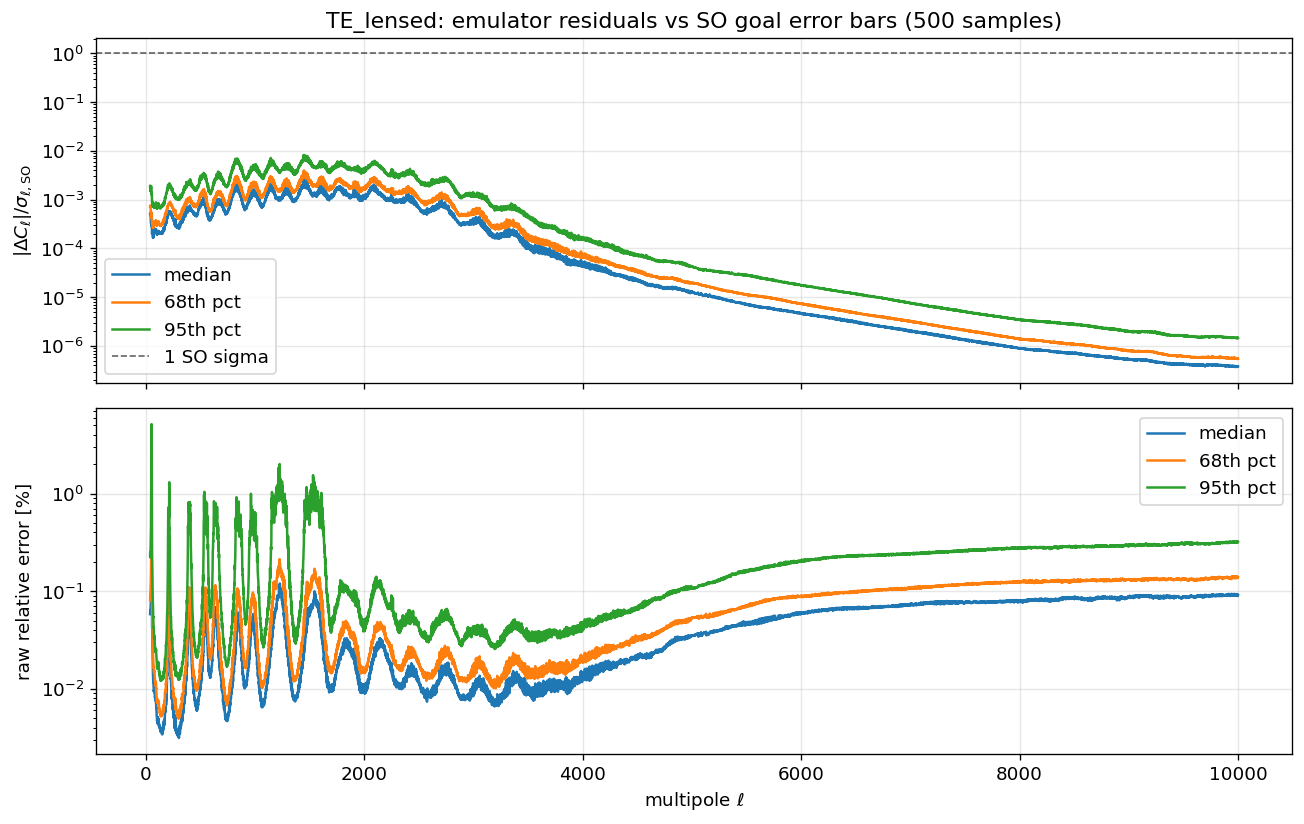

In [6]:
p_so = np.nanpercentile(so_units, [50, 68, 95], axis=0)
p_rel = 100 * np.nanpercentile(rel_err, [50, 68, 95], axis=0)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(ell_cmp, p_so[0], label="median")
axes[0].plot(ell_cmp, p_so[1], label="68th pct")
axes[0].plot(ell_cmp, p_so[2], label="95th pct")
axes[0].axhline(1, color="k", ls="--", lw=1, alpha=0.6, label="1 SO sigma")
axes[0].set_ylabel(r"$|\Delta C_\ell| / \sigma_{\ell,\mathrm{SO}}$")
axes[0].set_title(f"{SPECTRUM}: emulator residuals vs SO {SO_SENSITIVITY} error bars ({so_units.shape[0]} samples)")
axes[0].set_yscale("log")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(ell_cmp, p_rel[0], label="median")
axes[1].plot(ell_cmp, p_rel[1], label="68th pct")
axes[1].plot(ell_cmp, p_rel[2], label="95th pct")
axes[1].set_xlabel(r"multipole $\ell$")
axes[1].set_ylabel("raw relative error [%]")
axes[1].set_yscale("log")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

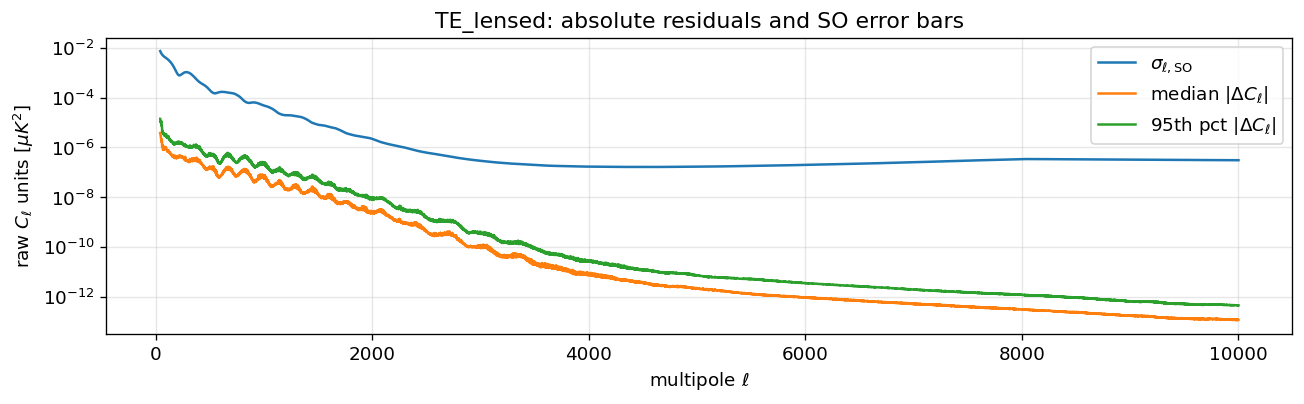

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(ell_cmp, sigma_cmp, label=r"$\sigma_{\ell,\mathrm{SO}}$")
ax.plot(ell_cmp, np.nanmedian(np.abs(delta), axis=0), label=r"median $|\Delta C_\ell|$")
ax.plot(ell_cmp, np.nanpercentile(np.abs(delta), 95, axis=0), label=r"95th pct $|\Delta C_\ell|$")
ax.set_xlabel(r"multipole $\ell$")
ax.set_ylabel(r"raw $C_\ell$ units [$\mu K^2$]")
ax.set_yscale("log")
ax.set_title(f"{SPECTRUM}: absolute residuals and SO error bars")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()